# Stage-1 Backbone Analysis: Frequency-Adaptive 2D RoPE and Spatial-Semantic Sparse Attention

This notebook inspects the mathematical formulation and internal representations of the `vit_small_sparse_rope` backbone (`models/rope.py` and `models/sparse_attention.py`).

### Architectural Formulation
1. **Frequency-Adaptive 2D Rotary Position Embedding (`FrequencyAdaptive2DRoPE`)**:
   - Replaces static 1D absolute positional embeddings with axial 2D complex rotations modulated by a frequency-dependent interpolation factor $\alpha_m$:
     $$\omega_m = B^{-2m / d_x}, \quad \alpha_m = 1 - \frac{m}{M-1} \in [0, 1], \quad m \in \{0, \dots, M-1\}$$
     $$x_m^{\text{adapt}} = \alpha_m \, x_{\text{raw}} + (1 - \alpha_m)\, x_{\text{norm}}, \quad y_m^{\text{adapt}} = \alpha_m \, y_{\text{raw}} + (1 - \alpha_m)\, y_{\text{norm}}$$
     $$\theta_{x,m} = x_m^{\text{adapt}}\, \omega_m, \quad \theta_{y,m} = y_m^{\text{adapt}}\, \omega_m$$
   - High-frequency bands ($m \to 0, \alpha_m \to 1$) preserve exact unit-step lattice offsets $p_{\text{raw}}$ for local edge fidelity, whereas low-frequency bands ($m \to M-1, \alpha_m \to 0$) follow normalized coordinates $p_{\text{norm}}$ for scale-invariant global geometry.

2. **Spatial-Semantic Sparse Softmax Attention (`SpatialSemanticAttention`)**:
   - Each query patch $i \in \{1, \dots, N\}$ restricts its softmax support to a sparse index set $\mathcal{S}_i$:
     $$\mathcal{S}_i = \mathcal{N}_{\text{local}}(i) \;\cup\; \text{Top-}K_{\text{sem}}\!\left(\frac{\mathbf{q}_i \mathbf{K}_{\notin \mathcal{N}_{\text{local}}(i)}^\top}{\sqrt{d_k}}\right) \;\cup\; \{\text{CLS}\}$$

In [1]:
import os, sys, math, glob
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms

if os.path.exists("/Users/KhangDS/Programing/HCMUS_Code/ComputerVision_code/DINOv1"):
    os.chdir("/Users/KhangDS/Programing/HCMUS_Code/ComputerVision_code/DINOv1")
    if os.getcwd() not in sys.path:
        sys.path.insert(0, os.getcwd())

from core.registry import MODULES
import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams["figure.dpi"] = 130
print(f"Device: {device} | Working directory: {os.getcwd()}")

Device: cpu | Working directory: /Users/KhangDS/Programing/HCMUS_Code/ComputerVision_code/DINOv1


## 1. Frequency-Adaptive 2D RoPE Spectrum and Spatial Basis Functions
For `vit_small_sparse_rope` ($D=384, H=6$), each attention head has dimension $d_k = 64$:
- $d_x = 32$ dimensions encode horizontal coordinates across $M = d_x / 2 = 16$ frequency bands.
- $d_y = 32$ dimensions encode vertical coordinates across $M = d_y / 2 = 16$ frequency bands.
- Queries and keys are rotated via pairwise 2D orthogonal transformations:
  $$\text{rotate\_half}([u_0, u_1, u_2, u_3, \dots]) = [-u_1, u_0, -u_3, u_2, \dots]$$
  $$\mathbf{q}^{\text{rot}} = \mathbf{q} \odot \cos\boldsymbol{\theta} + \text{rotate\_half}(\mathbf{q}) \odot \sin\boldsymbol{\theta}$$

[CLS] Token rotation identity check at index 0: cos=[1.0, 1.0, 1.0, 1.0], sin=[0.0, 0.0, 0.0, 0.0]


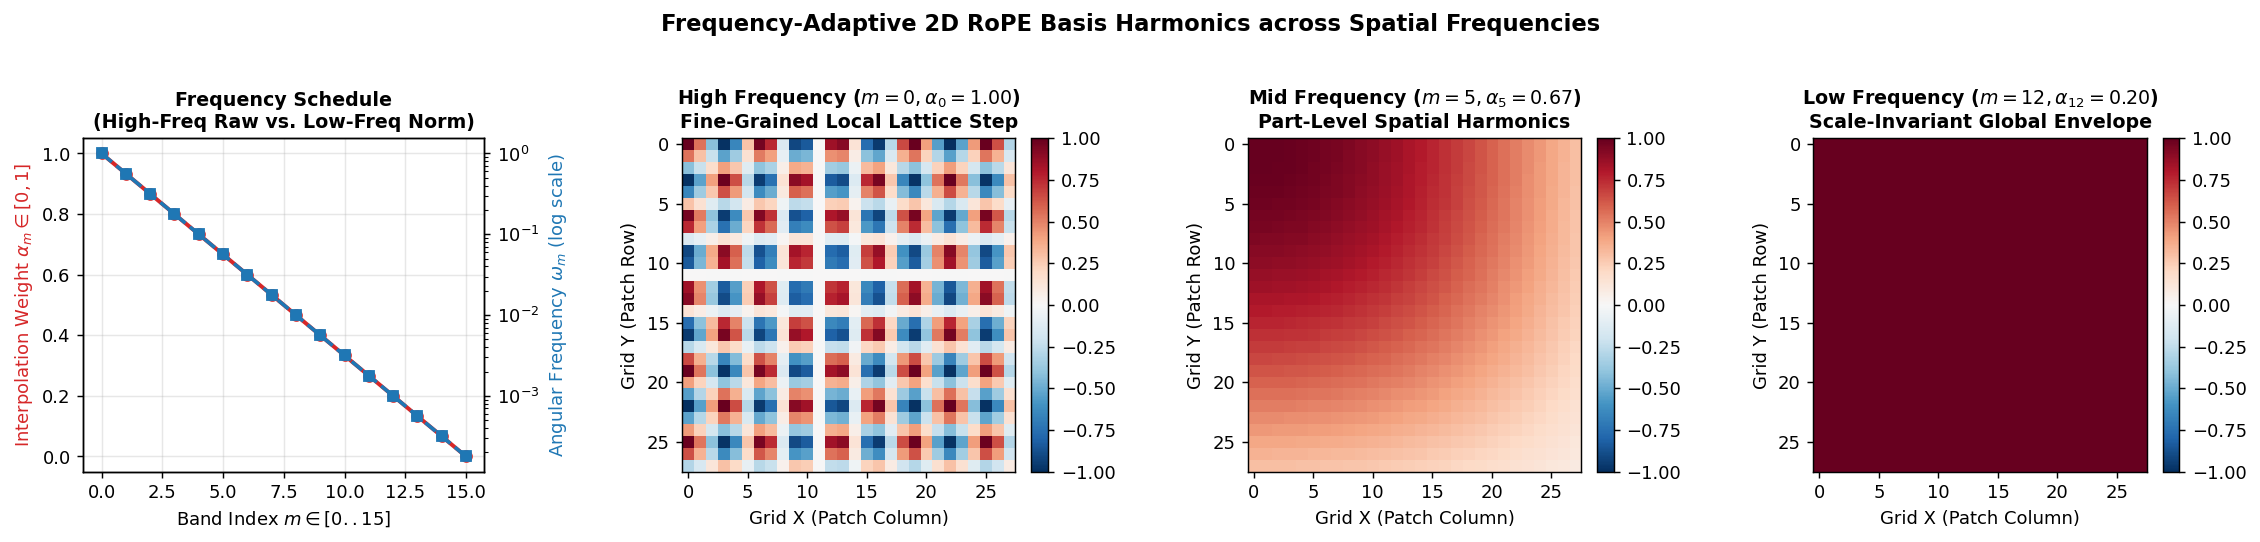

In [2]:
rope_adaptive = MODULES.build({
    "type": "FrequencyAdaptive2DRoPE",
    "dim": 64,
    "ref_img_size": 224,
    "patch_size": 16,
    "base": 10000.0,
    "mode": "adaptive_2d",
})

inv_freq = rope_adaptive.inv_freq.numpy()          # (16,)
alpha_vals = rope_adaptive.get_alpha().numpy()     # (16,)
bands = np.arange(len(inv_freq))

grid_high = (28, 28)
cos_28, sin_28 = rope_adaptive.compute_freqs_cis(
    grid_size=grid_high, device=torch.device("cpu"), dtype=torch.float32, has_cls_token=True
)
cos_spatial = cos_28[1:].view(28, 28, 64).numpy()

fig, axes = plt.subplots(1, 4, figsize=(17.5, 4.0))

ax0 = axes[0]
ax0_twin = ax0.twinx()
ax0.plot(bands, alpha_vals, "o-", color="#d62728", linewidth=2.2, label=r"Adaptive Weight $\alpha_m$")
ax0_twin.plot(bands, inv_freq, "s--", color="#1f77b4", linewidth=2.0, label=r"Frequency $\omega_m$")
ax0.set_title("Frequency Schedule\n(High-Freq Raw vs. Low-Freq Norm)", fontweight="bold", fontsize=10.5)
ax0.set_xlabel(r"Band Index $m \in [0..15]$")
ax0.set_ylabel(r"Interpolation Weight $\alpha_m \in [0, 1]$", color="#d62728")
ax0_twin.set_ylabel(r"Angular Frequency $\omega_m$ (log scale)", color="#1f77b4")
ax0_twin.set_yscale("log")
ax0.grid(True, alpha=0.3)

for idx, (m_band, title_tag) in enumerate([
    (0, "High Frequency ($m=0, \\alpha_0=1.00$)\nFine-Grained Local Lattice Step"),
    (5, "Mid Frequency ($m=5, \\alpha_5=0.67$)\nPart-Level Spatial Harmonics"),
    (12, "Low Frequency ($m=12, \\alpha_{12}=0.20$)\nScale-Invariant Global Envelope"),
], start=1):
    dim_x_idx = 2 * m_band
    dim_y_idx = 32 + 2 * m_band
    wave_2d = cos_spatial[:, :, dim_x_idx] * cos_spatial[:, :, dim_y_idx]
    im = axes[idx].imshow(wave_2d, cmap="RdBu_r", vmin=-1.0, vmax=1.0)
    axes[idx].set_title(title_tag, fontweight="bold", fontsize=10.5)
    axes[idx].set_xlabel("Grid X (Patch Column)")
    axes[idx].set_ylabel("Grid Y (Patch Row)")
    plt.colorbar(im, ax=axes[idx], fraction=0.046, pad=0.04)

plt.suptitle("Frequency-Adaptive 2D RoPE Basis Harmonics across Spatial Frequencies", fontsize=12.5, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

print(f"[CLS] Token rotation identity check at index 0: cos={cos_28[0, :4].tolist()}, sin={sin_28[0, :4].tolist()}")

## 2. Relative Positional Decay Across Resolution Extrapolation ($14 \times 14 \to 28 \times 28$)
For uniform query and key vectors ($\mathbf{q}_c = \mathbf{k}_j = \mathbf{1}$), the inner product after applying 2D RoPE reduces strictly to a function of 2D relative displacement $(\Delta x, \Delta y)$:
$$\langle \mathbf{q}_c^{\text{rot}},\, \mathbf{k}_j^{\text{rot}} \rangle = \sum_{m=0}^{M-1} 2\cos\!\big(\Delta x_m^{\text{adapt}} \omega_m\big) + \sum_{m=0}^{M-1} 2\cos\!\big(\Delta y_m^{\text{adapt}} \omega_m\big)$$

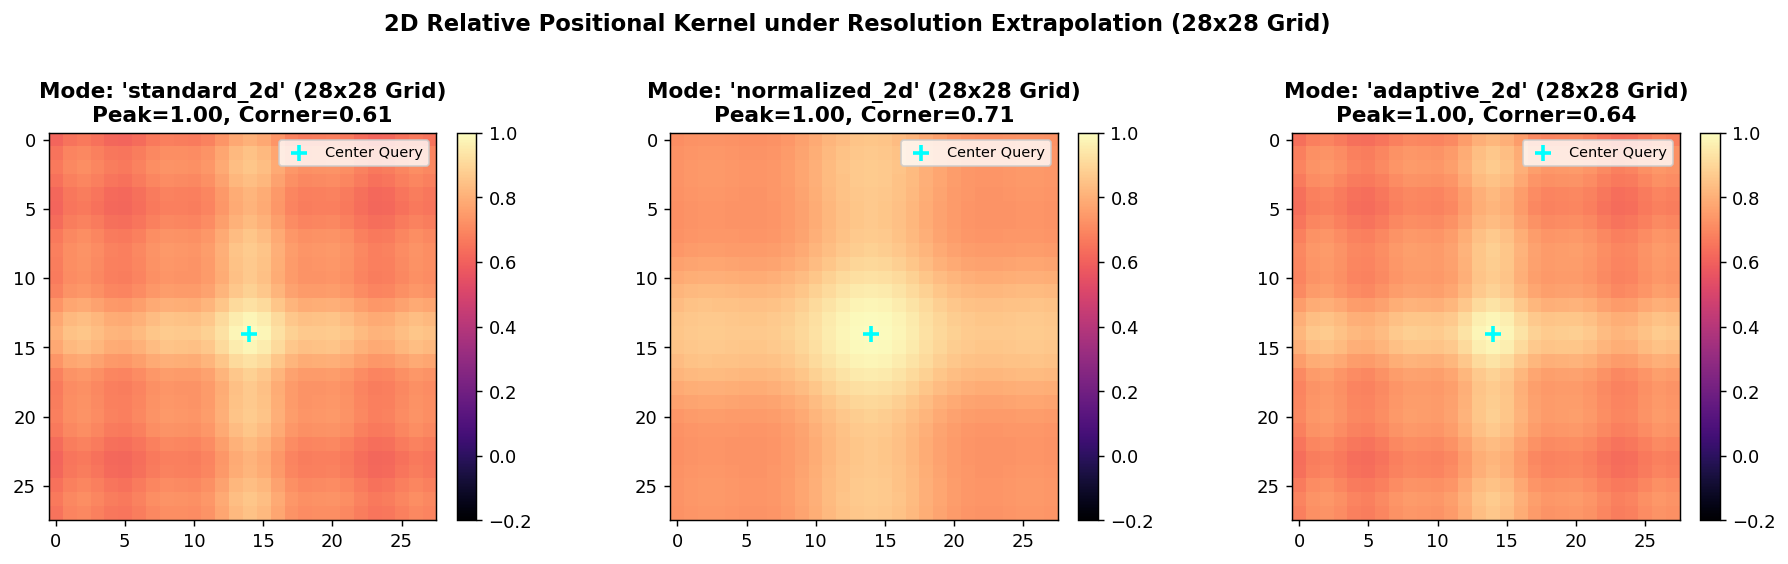

In [3]:
modes = ["standard_2d", "normalized_2d", "adaptive_2d"]
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.1))

H_test, W_test = 28, 28
center_idx = 1 + (H_test // 2) * W_test + (W_test // 2)

for ax, mode_name in zip(axes, modes):
    rope_m = MODULES.build({
        "type": "FrequencyAdaptive2DRoPE",
        "dim": 64,
        "ref_img_size": 224,
        "patch_size": 16,
        "mode": mode_name,
    })
    ones_q = torch.ones(1, 1, 1 + H_test * W_test, 64)
    q_rot, k_rot = rope_m(ones_q, ones_q, grid_size=(H_test, W_test), has_cls_token=True)
    rel_kernel = (q_rot[0, 0, center_idx : center_idx + 1, :] @ k_rot[0, 0, 1:, :].T).view(H_test, W_test) / 64.0
    im = ax.imshow(rel_kernel.numpy(), cmap="magma", vmin=-0.2, vmax=1.0)
    ax.scatter([W_test // 2], [H_test // 2], c="cyan", s=70, marker="+", linewidths=2, label="Center Query")
    ax.set_title(f"Mode: '{mode_name}' (28x28 Grid)\nPeak={rel_kernel.max():.2f}, Corner={rel_kernel[0,0]:.2f}", fontweight="bold")
    ax.legend(loc="upper right", fontsize=8)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle("2D Relative Positional Kernel under Resolution Extrapolation (28x28 Grid)", fontsize=12.5, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

## 3. Spatial-Semantic Sparse Attention ($S^3$) Mask Decomposition
Below we load the pre-trained `vit_small_sparse_rope` checkpoint (`cp/checkpoints_rope_2/checkpoint0190.pth`) and decompose the exact sparse attention support $\mathcal{S}_{i^*}$ for a selected query patch $i^*$:
- **Local Spatial Window $\mathcal{N}_{\text{local}}(i^*)$**: $3 \times 3$ spatial neighborhood around patch $i^*$ plus bidirectional `[CLS]` routing.
- **Global Semantic Top-$K$ $\mathcal{N}_{\text{semantic}}(i^*)$**: Top-$16$ non-local patches with highest dot-product similarity:
  $$\mathcal{N}_{\text{semantic}}(i^*) = \text{Top-}16_{j \notin \mathcal{N}_{\text{local}}(i^*)}\!\left(\frac{\langle \mathbf{q}_{i^*}^{\text{rot}},\, \mathbf{k}_j^{\text{rot}} \rangle}{\sqrt{d_k}}\right)$$

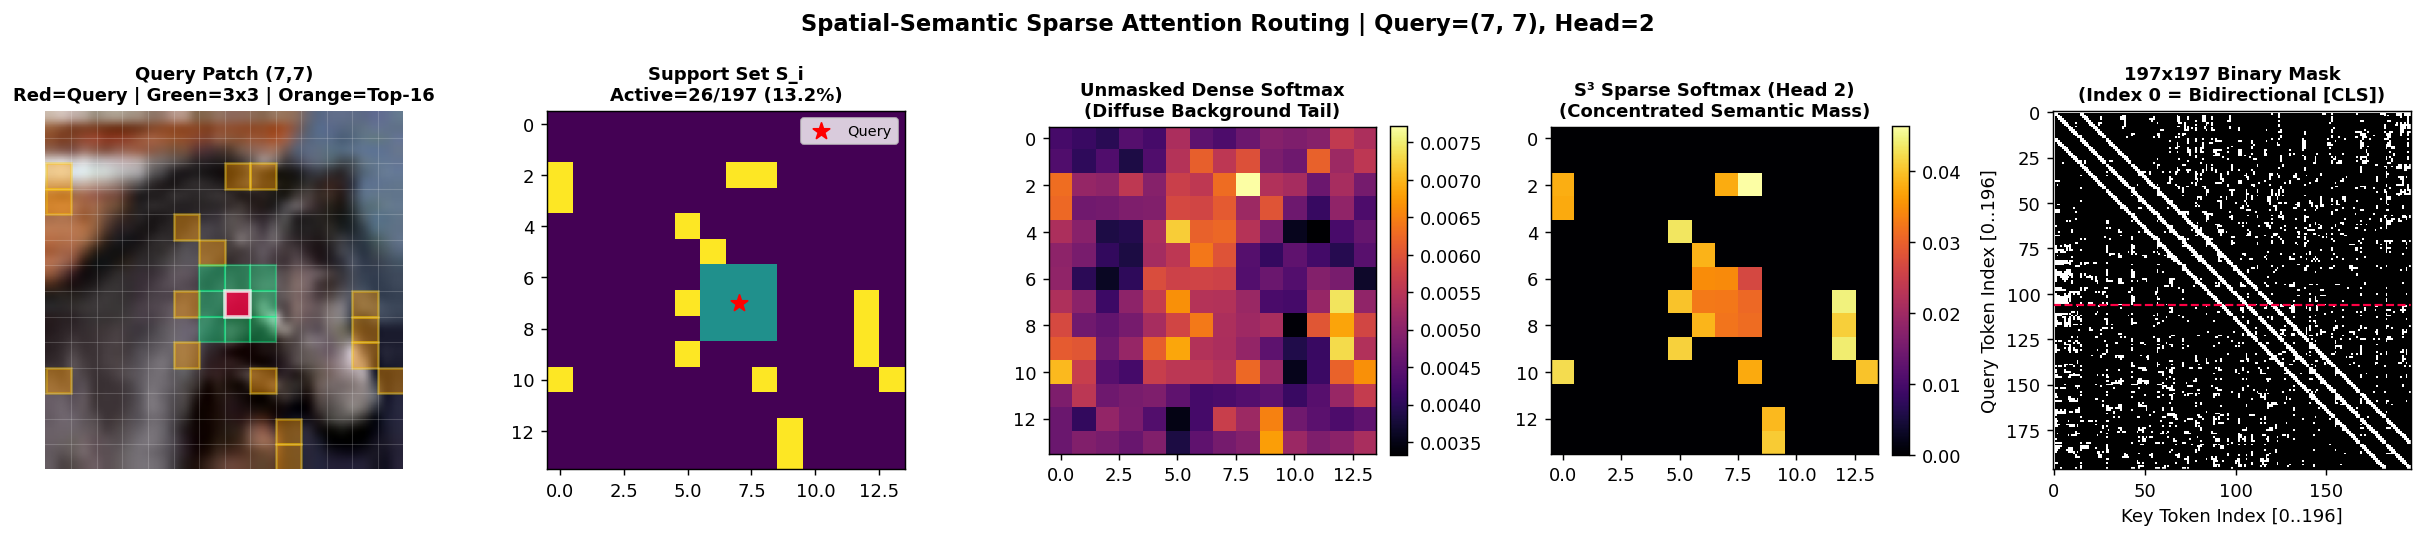

In [4]:
from train_grpo_post import resolve_checkpoint_path

rope_ckpt_path = resolve_checkpoint_path("cp/checkpoints_rope_2/checkpoint0190.pth")
stage1_rope_wrapper = MODULES.build({
    "type": "DINOGRPOPolicyWrapper",
    "arch": "auto",
    "patch_size": 16,
    "pretrained_weights": rope_ckpt_path,
}).to(device).eval()

horse_candidates = sorted(glob.glob("data/cifar10/val/horse/*.png"))
sample_img_path = horse_candidates[24] if len(horse_candidates) > 24 else horse_candidates[0]

raw_pil = Image.open(sample_img_path).convert("RGB").resize((224, 224), Image.BICUBIC)
val_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
])
img_tensor = val_tf(raw_pil).unsqueeze(0).to(device)


def inspect_s3_sparse_routing(query_row: int = 7, query_col: int = 7, head_idx: int = 2) -> None:
    '''Visualizes the local window mask, semantic top-k selection, and resulting sparse softmax distribution.'''
    backbone = stage1_rope_wrapper.backbone
    with torch.no_grad():
        tokens, grid_size = backbone.prepare_tokens(img_tensor)
        for blk in backbone.blocks[:-1]:
            tokens = blk(tokens, grid_size=grid_size)
        last_blk = backbone.blocks[-1]
        x_norm = last_blk.norm1(tokens)
        attn_mod = last_blk.attn

        B, N, C = x_norm.shape
        qkv = attn_mod.qkv(x_norm).reshape(B, N, 3, attn_mod.num_heads, attn_mod.head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        if attn_mod.rope is not None:
            q, k = attn_mod.rope(q, k, grid_size=grid_size, has_cls_token=True)

        sim = (q @ k.transpose(-2, -1)) * attn_mod.scale
        local_mask = attn_mod.get_local_mask(grid_size, has_cls_token=True, device=device)
        combined_mask = attn_mod.build_attention_mask(sim, grid_size, has_cls_token=True)
        semantic_only_mask = combined_mask[0, head_idx] & (~local_mask)

        dense_attn = F.softmax(sim[0, head_idx], dim=-1)
        sparse_attn = F.softmax(sim[0, head_idx].masked_fill(~combined_mask[0, head_idx], float("-inf")), dim=-1)

    q_token_idx = 1 + query_row * 14 + query_col
    loc_2d = local_mask[q_token_idx, 1:].view(14, 14).cpu().numpy().astype(float)
    sem_2d = semantic_only_mask[q_token_idx, 1:].view(14, 14).cpu().numpy().astype(float)
    sparse_weights_2d = sparse_attn[q_token_idx, 1:].view(14, 14).cpu().numpy()
    dense_weights_2d = dense_attn[q_token_idx, 1:].view(14, 14).cpu().numpy()

    active_count = int(combined_mask[0, head_idx, q_token_idx].sum().item())
    sparsity_pct = 100.0 * active_count / 197.0

    fig, axes = plt.subplots(1, 5, figsize=(18.5, 3.8))

    axes[0].imshow(raw_pil)
    for g in range(1, 14):
        axes[0].axhline(g * 16, color="white", alpha=0.18, linewidth=0.6)
        axes[0].axvline(g * 16, color="white", alpha=0.18, linewidth=0.6)
    for r in range(14):
        for c in range(14):
            if loc_2d[r, c] > 0.5 and not (r == query_row and c == query_col):
                rect = plt.Rectangle((c * 16, r * 16), 16, 16, fill=True, facecolor="#00ff88", alpha=0.32, edgecolor="#00ff88", linewidth=1.2)
                axes[0].add_patch(rect)
            elif sem_2d[r, c] > 0.5:
                rect = plt.Rectangle((c * 16, r * 16), 16, 16, fill=True, facecolor="#ff9900", alpha=0.42, edgecolor="#ffcc00", linewidth=1.4)
                axes[0].add_patch(rect)
    q_rect = plt.Rectangle((query_col * 16, query_row * 16), 16, 16, fill=True, facecolor="#ff0044", alpha=0.75, edgecolor="white", linewidth=2.0)
    axes[0].add_patch(q_rect)
    axes[0].set_title(f"Query Patch ({query_row},{query_col})\nRed=Query | Green=3x3 | Orange=Top-16", fontweight="bold", fontsize=10)
    axes[0].axis("off")

    comp_map = loc_2d * 1.0 + sem_2d * 2.0
    axes[1].imshow(comp_map, cmap="viridis", vmin=0, vmax=2)
    axes[1].scatter([query_col], [query_row], c="red", s=90, marker="*", label="Query")
    axes[1].set_title(f"Support Set S_i\nActive={active_count}/197 ({sparsity_pct:.1f}%)", fontweight="bold", fontsize=10)
    axes[1].legend(loc="upper right", fontsize=8)

    im2 = axes[2].imshow(dense_weights_2d, cmap="inferno")
    axes[2].set_title("Unmasked Dense Softmax\n(Diffuse Background Tail)", fontweight="bold", fontsize=10)
    plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

    im3 = axes[3].imshow(sparse_weights_2d, cmap="inferno")
    axes[3].set_title(f"S³ Sparse Softmax (Head {head_idx})\n(Concentrated Semantic Mass)", fontweight="bold", fontsize=10)
    plt.colorbar(im3, ax=axes[3], fraction=0.046, pad=0.04)

    axes[4].imshow(combined_mask[0, head_idx].cpu().numpy(), cmap="Greys_r", interpolation="nearest")
    axes[4].axhline(q_token_idx, color="#ff0044", linewidth=1.2, linestyle="--")
    axes[4].set_title("197x197 Binary Mask\n(Index 0 = Bidirectional [CLS])", fontweight="bold", fontsize=10)
    axes[4].set_xlabel("Key Token Index [0..196]")
    axes[4].set_ylabel("Query Token Index [0..196]")

    plt.suptitle(
        f"Spatial-Semantic Sparse Attention Routing | Query=({query_row}, {query_col}), Head={head_idx}",
        fontsize=12.5, fontweight="bold", y=1.03
    )
    plt.tight_layout()
    plt.show()


inspect_s3_sparse_routing(query_row=7, query_col=7, head_idx=2)

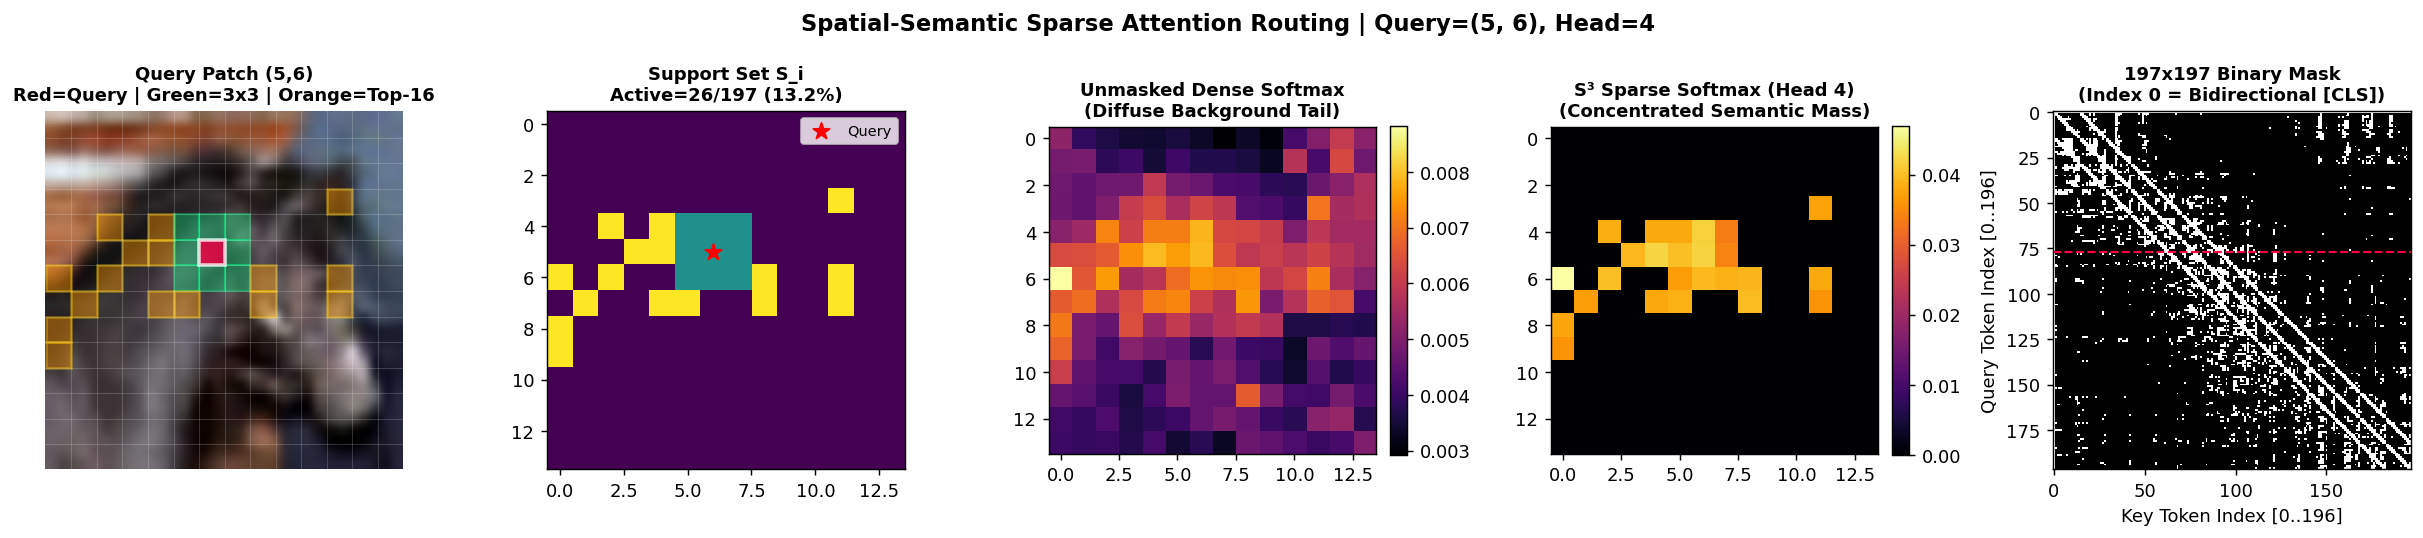

In [5]:
# Inspect an alternative query coordinate and attention head
try:
    import ipywidgets as widgets
    widgets.interact(
        inspect_s3_sparse_routing,
        query_row=widgets.IntSlider(min=0, max=13, step=1, value=5, description="Query Row:"),
        query_col=widgets.IntSlider(min=0, max=13, step=1, value=6, description="Query Col:"),
        head_idx=widgets.IntSlider(min=0, max=5, step=1, value=4, description="Head Index:"),
    )
except Exception:
    inspect_s3_sparse_routing(query_row=5, query_col=6, head_idx=4)